In [1]:
import os
import json
import numpy as np
import pandas as pd
import scipy
import matplotlib.pyplot as plt
import seaborn as sns

import main_analysis as ma

In [2]:
RESULTS_DIR = 'results'
MODELS_DIR = 'models'
PLOTS_DIR = f'{RESULTS_DIR}/plots'
os.makedirs(PLOTS_DIR, exist_ok=True)

MODELS_INFO_CSV_PATH = f'{RESULTS_DIR}/models_info.csv'
SUBJECTSUBJECT_CORRELATIONS_CSV_PATH = f'{RESULTS_DIR}/subjectsubject_correlations_nsd515.csv'
MODELSUBJECT_CORRELATIONS_CSV_PATH = f'{RESULTS_DIR}/modelsubject_correlations_nsd515.csv'

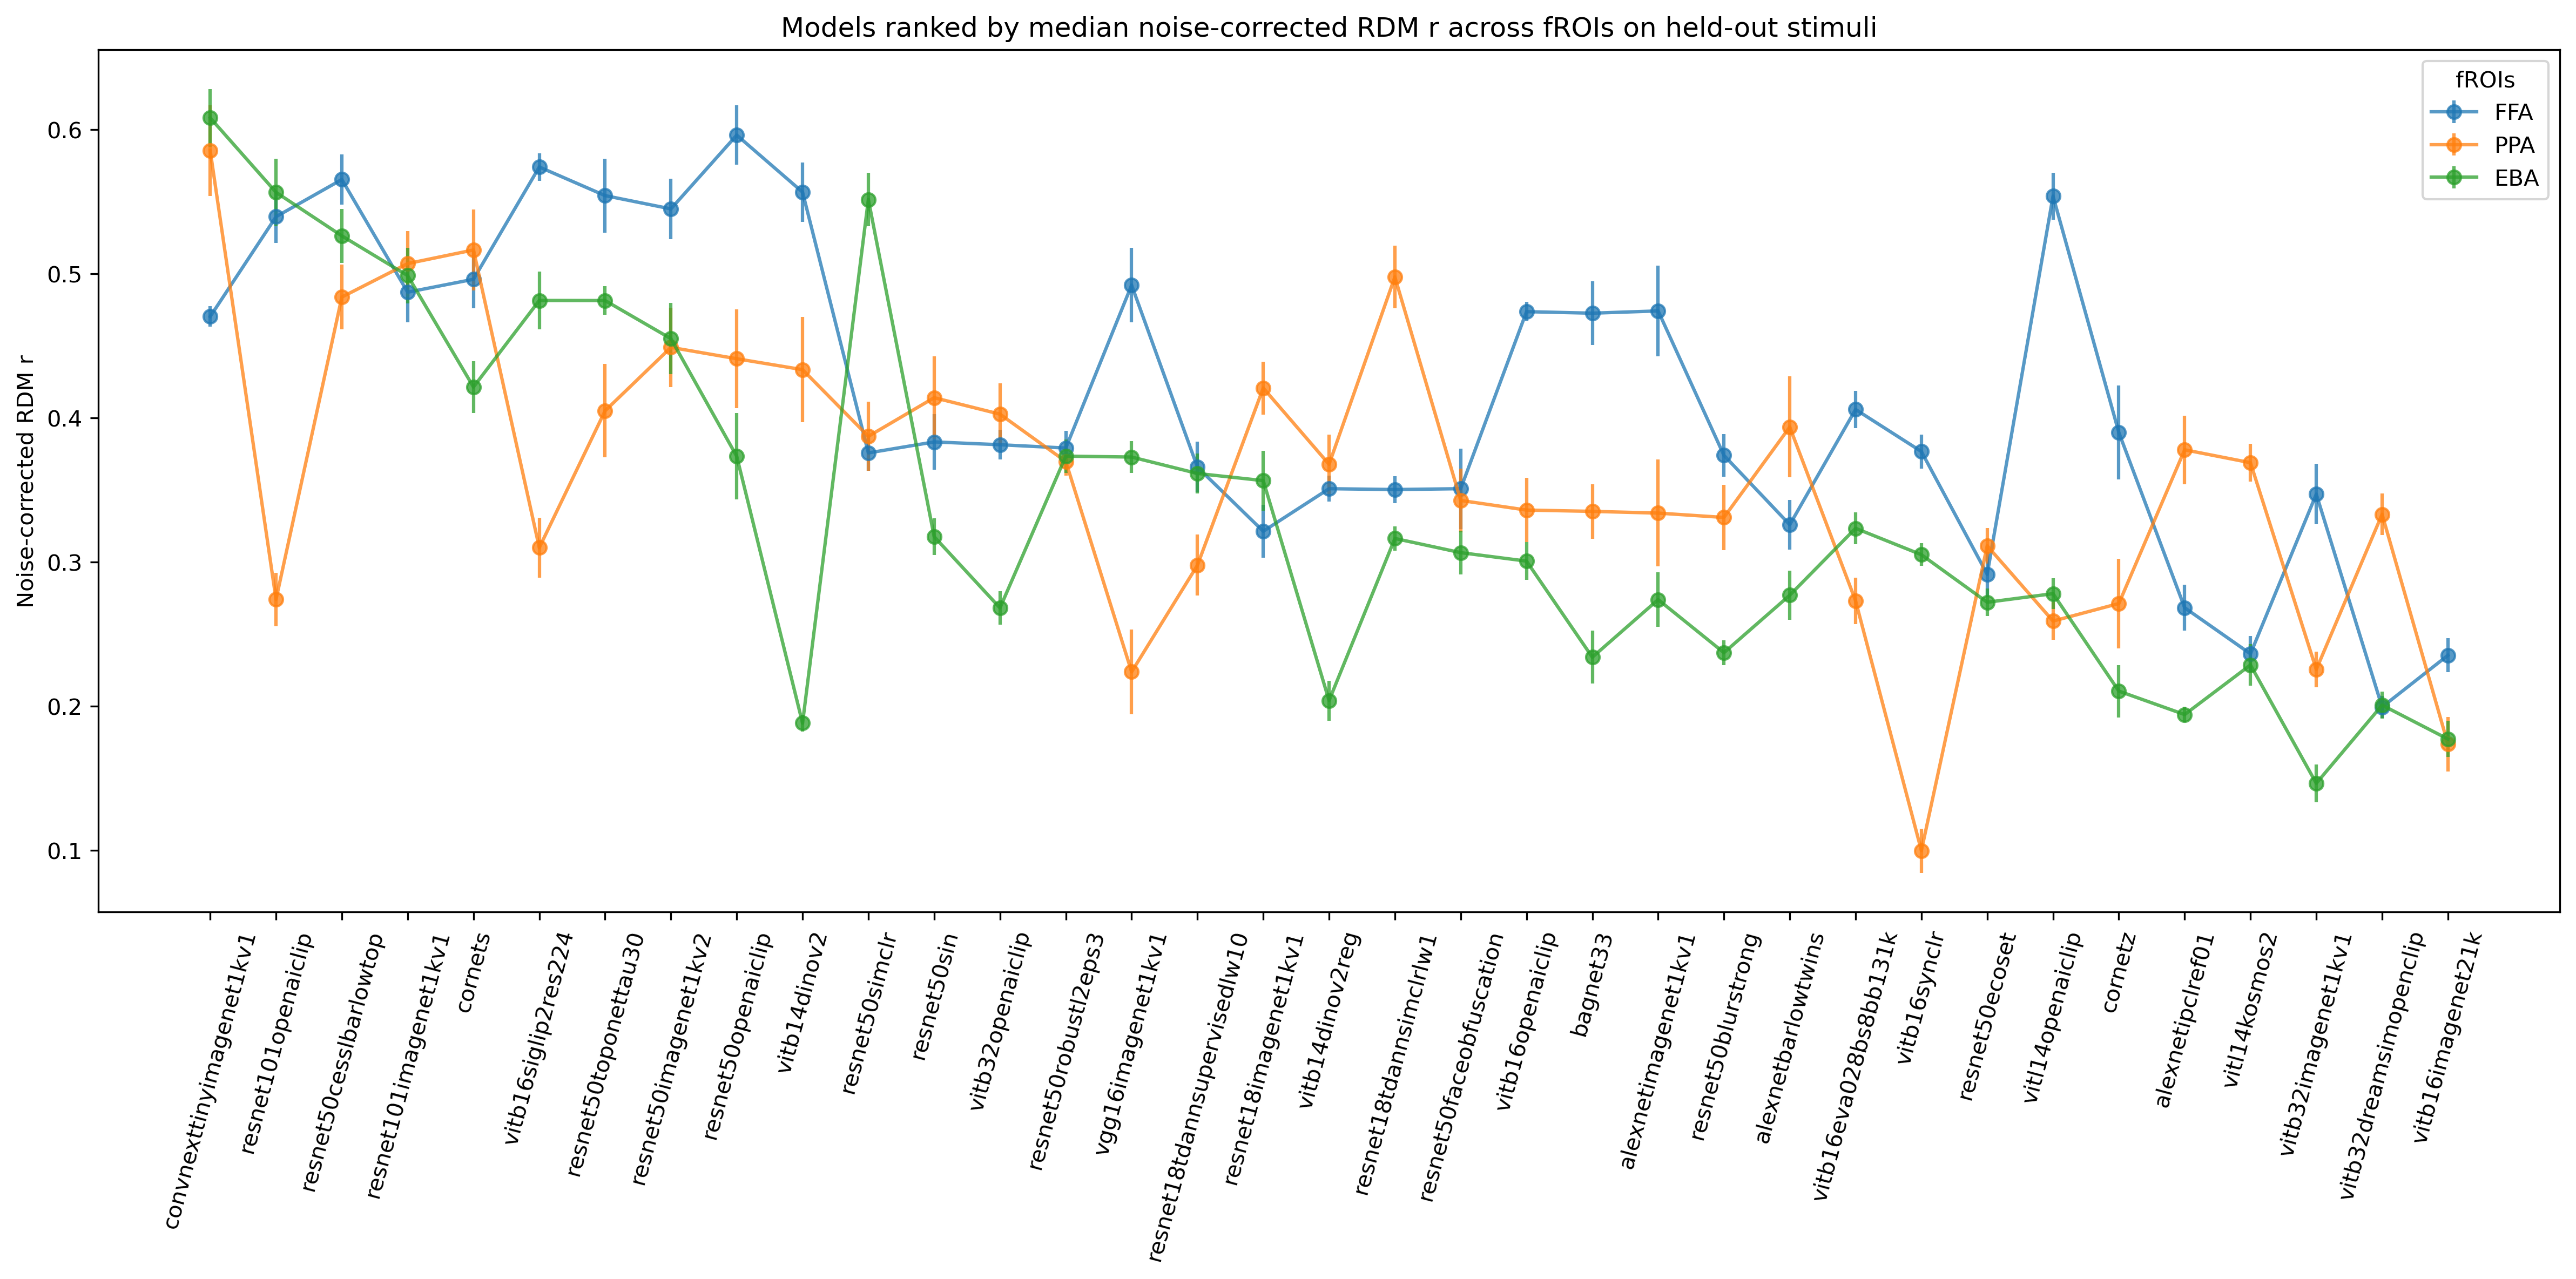

In [46]:
# Model ranks for FFA, PPA, EBA

plot_dir = f'{PLOTS_DIR}/modelranks'
os.makedirs(plot_dir, exist_ok=True)
selected_frois = ['FFA', 'PPA', 'EBA']

modelsubject_univariate_csv = pd.read_csv(MODELSUBJECT_CORRELATIONS_CSV_PATH)

modelsubject_univariate_csv = modelsubject_univariate_csv[
    (modelsubject_univariate_csv['model_froi'].isin(selected_frois)) &
    (modelsubject_univariate_csv['fmri_froi'].isin(selected_frois))
]
model_names = modelsubject_univariate_csv['model_name'].unique().tolist()

fmri_frois = modelsubject_univariate_csv['fmri_froi'].unique().tolist()
median_normed_rdmr =modelsubject_univariate_csv.groupby(['model_name', 'model_froi', 'fmri_froi'])['normed_rdmr'].median().reset_index()
sem_normed_rdmr = modelsubject_univariate_csv.groupby(['model_name', 'model_froi', 'fmri_froi'])['normed_rdmr'].sem().reset_index()

# Take median across frois and get model ranks
median_normed_rdmr_across_frois = median_normed_rdmr.groupby(['model_name'])['normed_rdmr'].median().reset_index()
median_normed_rdmr_across_frois_sorted = median_normed_rdmr_across_frois.sort_values(by='normed_rdmr', ascending=False)
sorted_model_names = median_normed_rdmr_across_frois_sorted['model_name'].tolist()
# Get a dictionary of model ranks
# model_ranks = {}
# for rank, (idx, row) in enumerate(median_normed_rdmr_across_frois_sorted.iterrows(), start=1):
#     model_ranks[row['model_name']] = rank

all_values = {}
for model_name in sorted_model_names:
    for froi in fmri_frois:
        model_froi_median_normed_rdmr_df = median_normed_rdmr[
            (median_normed_rdmr['model_name'] == model_name) &
            (median_normed_rdmr['model_froi'] == froi) &
            (median_normed_rdmr['fmri_froi'] == froi)
        ]
        assert len(model_froi_median_normed_rdmr_df) == 1, "Expected exactly one entry for each model and fROI combination"
        median_value = model_froi_median_normed_rdmr_df['normed_rdmr'].values[0]
        model_froi_sem_normed_rdmr_df = sem_normed_rdmr[
            (sem_normed_rdmr['model_name'] == model_name) &
            (sem_normed_rdmr['model_froi'] == froi) &
            (sem_normed_rdmr['fmri_froi'] == froi)
        ]
        assert len(model_froi_sem_normed_rdmr_df) == 1, "Expected exactly one entry for each model and fROI combination"
        sem_value = model_froi_sem_normed_rdmr_df['normed_rdmr'].values[0]
        if froi not in all_values:
            all_values[froi] = []
        all_values[froi].append((median_value.item(), sem_value.item()))

# Create a scatter plot
fig, ax = plt.subplots(figsize=(16, 8), dpi=300)

# Plot the scaled_normed_pearsonr for each fROI and connect them across models
for froi in selected_frois:
    x_points = sorted_model_names
    y_points = np.array(all_values[froi])[:, 0]
    yerrs = np.array(all_values[froi])[:, 1]
    ax.errorbar(
        x_points, y_points, yerr=yerrs, marker='o', label=froi, alpha=0.75, capsize=0, linestyle='-'
    )
    # ax.plot(
    #     x_points, y_points, marker='o', label=froi, alpha=0.75
    # )

# Add a vertical dotted line at the median model
# median_model_idx = len(all_values_sorted) // 2
# median_model_name = all_values_sorted.iloc[median_model_idx]['model_name']
# ax.axvline(x=median_model_name, color='k', linestyle='--', linewidth=1, label='Median')

# ax.set_xlabel('Models')
ax.set_ylabel(r'Noise-corrected RDM r')
ax.set_title('Models ranked by median noise-corrected RDM r across fROIs on held-out stimuli')
plt.xticks(rotation=75)
plt.legend(title='fROIs')
plt.tight_layout()
plt.show()
# plt.savefig(f'{plot_dir}/modelranks_across_frois.pdf')
plt.close()